# Import

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Core update function

In [10]:
def bayesian_update(heads: int, tails: int, prior_alpha: float = 1.0, prior_beta: float = 1.0):
    """
    Update a Beta prior with observed coin flip data.

    Beta(alpha, beta) is conjugate to the Binomial likelihood,
    so the posterior is simply Beta(alpha + heads, beta + tails).

    Args:
        heads: number of heads observed
        tails: number of tails observed
        prior_alpha: alpha parameter of the prior Beta distribution
        prior_beta: beta parameter of the prior Beta distribution

    Returns:
        posterior_alpha, posterior_beta
    """
    posterior_alpha = prior_alpha + heads
    posterior_beta  = prior_beta + tails
    return posterior_alpha, posterior_beta


# Visualization 1 — Sequential posterior updates

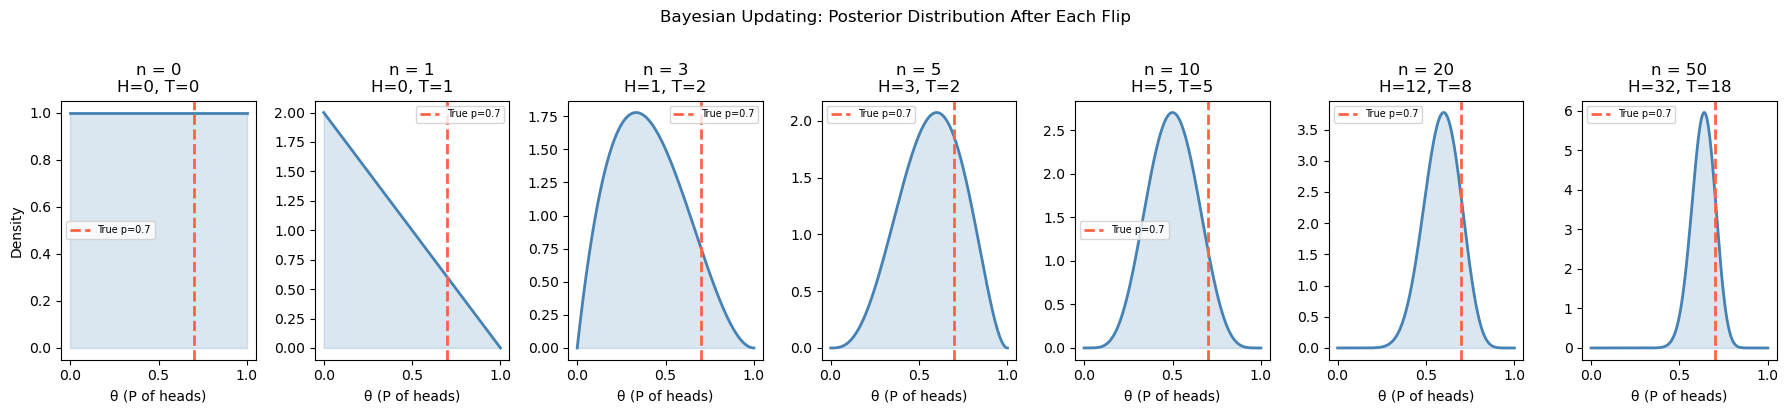

In [12]:
true_p = 0.7
n_flips = 50
prior_alpha = 1.0
prior_beta  = 1.0

rng = np.random.default_rng(42)
flips = rng.binomial(1, true_p, size=n_flips)

snapshots = [0, 1, 3, 5, 10, 20, 50]
theta = np.linspace(0, 1, 300)

fig, axes = plt.subplots(1, len(snapshots), figsize=(18, 4), sharey=False)

for ax, n in zip(axes, snapshots):
    heads = flips[:n].sum()
    tails = n - heads
    a, b = bayesian_update(heads, tails, prior_alpha, prior_beta)
    posterior = beta.pdf(theta, a, b)

    ax.plot(theta, posterior, color='steelblue', lw=2)
    ax.fill_between(theta, posterior, alpha=0.2, color='steelblue')
    ax.axvline(true_p, color='tomato', lw=2, ls='--', label='True p=0.7')
    ax.set_title(f'n = {n}\nH={heads}, T={tails}')
    ax.set_xlabel('θ (P of heads)')
    if n == 0:
        ax.set_ylabel('Density')
    ax.legend(fontsize=7)

fig.suptitle('Bayesian Updating: Posterior Distribution After Each Flip', y=1.02)
plt.tight_layout()
plt.savefig('bayesian_updates.png', dpi=150, bbox_inches='tight')
plt.show()


## Sequential Posterior Updates

At n=0 the prior is completely flat — every value of θ is equally plausible. After just one flip (T=1), the posterior tilts toward lower values of θ. By n=5 a clear peak emerges around 0.5–0.7. At n=20 the distribution concentrates tightly around 0.6–0.7, and by n=50 (H=32, T=18) the posterior is a narrow bell centered very close to the true value of 0.7 (red dashed line). This sequence shows Bayesian updating in action: each new observation shifts and sharpens the belief.

n=0时先验完全平坦——θ的所有值都同等可能。仅一次抛掷（T=1）后，后验已向较低的θ值倾斜。n=5时峰值在0.5-0.7附近开始清晰出现。n=20时分布紧密集中在0.6-0.7区间，n=50时（H=32, T=18）后验已是一个集中在真实值0.7（红色虚线）附近的窄钟形。这一序列展示了贝叶斯更新的过程：每次新的观测都在移动并收窄信念。

# Visualization 2 — Effect of prior strength

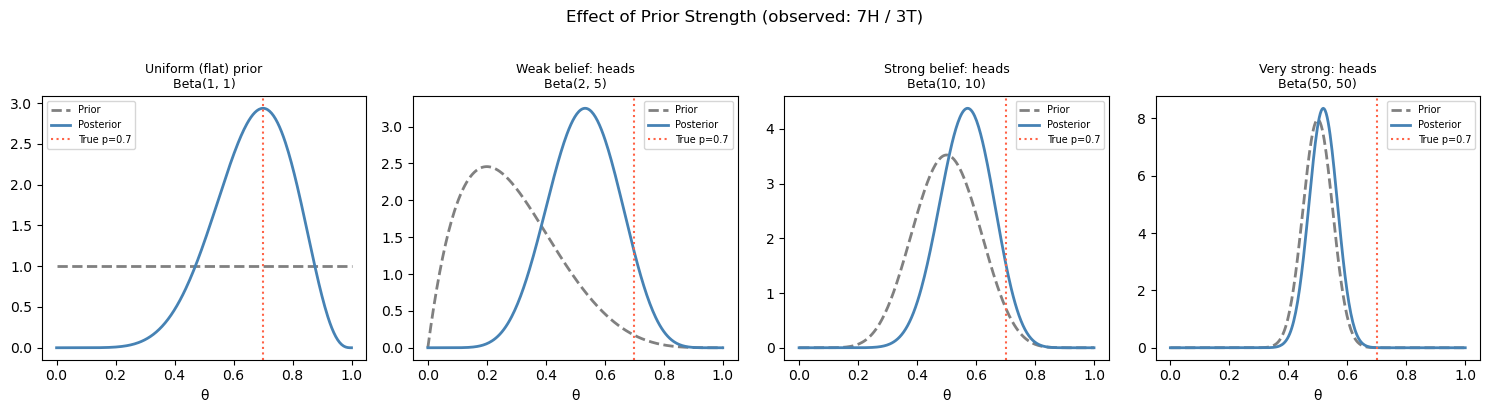

In [14]:
priors = {
    'Uniform (flat) prior\nBeta(1, 1)':  (1, 1),
    'Weak belief: heads\nBeta(2, 5)':    (2, 5),
    'Strong belief: heads\nBeta(10, 10)':(10, 10),
    'Very strong: heads\nBeta(50, 50)':  (50, 50),
}

obs_heads, obs_tails = 7, 3

fig, axes = plt.subplots(1, len(priors), figsize=(15, 4))

for ax, (name, (a0, b0)) in zip(axes, priors.items()):
    a_post, b_post = bayesian_update(obs_heads, obs_tails, a0, b0)
    prior_pdf     = beta.pdf(theta, a0, b0)
    posterior_pdf = beta.pdf(theta, a_post, b_post)

    ax.plot(theta, prior_pdf,     color='gray',      lw=2, ls='--', label='Prior')
    ax.plot(theta, posterior_pdf, color='steelblue', lw=2,          label='Posterior')
    ax.axvline(true_p, color='tomato', lw=1.5, ls=':', label='True p=0.7')
    ax.set_title(name, fontsize=9)
    ax.set_xlabel('θ')
    ax.legend(fontsize=7)

fig.suptitle(f'Effect of Prior Strength (observed: {obs_heads}H / {obs_tails}T)', y=1.02)
plt.tight_layout()
plt.savefig('bayesian_priors.png', dpi=150, bbox_inches='tight')
plt.show()


## Effect of Prior Strength

With a flat prior Beta(1,1), the posterior is driven entirely by the data and peaks near the observed proportion (7/10 = 0.7). With a weak contrary prior Beta(2,5) — which initially favors lower values — the posterior shifts toward the data but doesn’t fully reach 0.7. With a strong prior Beta(10,10) centered at 0.5, the posterior is pulled toward 0.5 and can’t overcome the prior’s influence with only 10 observations. With a very strong prior Beta(50,50), the posterior barely moves from the prior — 10 data points are simply insufficient to overcome 100 “virtual” prior observations. This illustrates a key principle: the stronger the prior, the more data you need to update your beliefs.

使用平坦先验Beta(1,1)时，后验完全由数据驱动，峰值接近观测比例（7/10=0.7）。使用弱的反向先验Beta(2,5)（初始偏向较低值）时，后验向数据方向移动，但未完全到达0.7。使用以0.5为中心的强先验Beta(10,10)时，后验被拉向0.5，仅10次观测不足以克服先验的影响。使用极强先验Beta(50,50)时，后验几乎没有从先验移动——10个数据点根本不足以克服相当于100次”虚拟”观测的先验。这揭示了一个关键原则：先验越强，需要越多数据才能更新信念。

# Visualization 3 — Posterior mean convergence

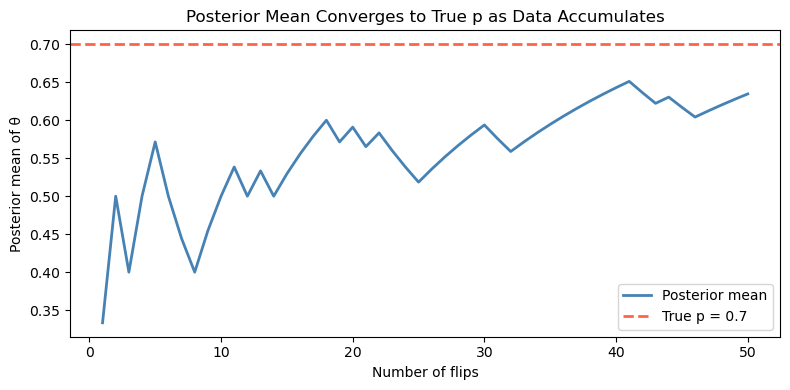

In [16]:
cumulative_heads = np.cumsum(flips)
cumulative_flips = np.arange(1, n_flips + 1)
posterior_means  = (prior_alpha + cumulative_heads) / (prior_alpha + prior_beta + cumulative_flips)

plt.figure(figsize=(8, 4))
plt.plot(cumulative_flips, posterior_means, color='steelblue', lw=2, label='Posterior mean')
plt.axhline(true_p, color='tomato', lw=2, ls='--', label=f'True p = {true_p}')
plt.xlabel('Number of flips')
plt.ylabel('Posterior mean of θ')
plt.title('Posterior Mean Converges to True p as Data Accumulates')
plt.legend()
plt.tight_layout()
plt.savefig('bayesian_convergence.png', dpi=150)
plt.show()


## Posterior Mean Convergence

With only 50 flips, the posterior mean has not yet fully converged to the true value of 0.7 — it fluctuates between 0.33 and 0.65, ending around 0.63. This is expected: 50 observations is a small sample for estimating a probability, and the flat prior starts the mean at 0.5. The overall upward trend confirms that the posterior mean is moving in the right direction. With several hundred flips, the curve would settle much closer to 0.7.

仅50次抛掷，后验均值尚未完全收敛到真实值0.7——它在0.33到0.65之间波动，最终约为0.63。这是正常的：50次观测对于估计一个概率来说样本量较小，而平坦先验使均值从0.5起步。整体上升趋势确认后验均值在向正确方向移动。若有几百次抛掷，曲线会更接近0.7。


#  Visualization 4 — Credible interval narrowing

ci_lowers, ci_uppers = [], []

for n in range(1, n_flips + 1):
    h = flips[:n].sum()
    t = n - h
    a, b = bayesian_update(h, t, prior_alpha, prior_beta)
    lo, hi = beta.ppf([0.025, 0.975], a, b)
    ci_lowers.append(lo)
    ci_uppers.append(hi)

ns = np.arange(1, n_flips + 1)

plt.figure(figsize=(8, 4))
plt.fill_between(ns, ci_lowers, ci_uppers, alpha=0.3, color='steelblue', label='95% credible interval')
plt.plot(ns, posterior_means, color='steelblue', lw=2, label='Posterior mean')
plt.axhline(true_p, color='tomato', lw=2, ls='--', label=f'True p = {true_p}')
plt.xlabel('Number of flips')
plt.ylabel('θ')
plt.title('95% Credible Interval Narrows as Evidence Accumulates')
plt.legend()
plt.tight_layout()
plt.savefig('bayesian_credible_interval.png', dpi=150)
plt.show()


## Credible Interval Narrowing

At n=1 the 95% credible interval spans nearly the full range [0.02, 0.91] — we know almost nothing. By n=20 it narrows to roughly [0.35, 0.80], and by n=50 to approximately [0.50, 0.76]. The true value of 0.7 remains within the interval throughout, confirming the credible interval is working correctly. The shaded band visibly shrinks as evidence accumulates, directly showing how Bayesian uncertainty decreases with more data. Note the interval is asymmetric at small n, reflecting the skewed shape of the Beta posterior early on.

n=1时95%可信区间几乎覆盖全范围[0.02, 0.91]——我们几乎什么都不知道。到n=20时收窄至约[0.35, 0.80]，n=50时约为[0.50, 0.76]。真实值0.7在整个过程中始终在区间内，确认了可信区间运作正确。阴影区域随证据积累明显收窄，直观展示了贝叶斯不确定性随数据增加而减少的过程。注意在小n时区间是不对称的，反映了早期Beta后验分布的偏态形状。

# Summary

Four visualizations build a complete picture of Bayesian inference:

1.	The sequential update plot shows how the posterior transitions from a flat uniform distribution to a narrow bell centered near the true value of 0.7 as more flips are observed — each observation shifts and sharpens the belief;
2.	The prior strength comparison demonstrates that stronger priors require more data to overcome: with Beta(50,50), even 10 observations barely move the posterior, while a flat prior lets the data speak entirely for itself;
3.	The posterior mean convergence plot tracks the point estimate over time, showing a noisy but upward trend toward the true value — 50 flips are not yet enough for full convergence, highlighting the role of sample size in Bayesian inference;
4.	The credible interval plot shows the 95% credible interval narrowing from nearly [0, 1] at n=1 to roughly [0.50, 0.76] at n=50, with the true value remaining inside throughout — directly visualizing how uncertainty shrinks as evidence accumulates.

Overall, this project illustrates the core Bayesian principle: beliefs are not fixed but updated continuously in light of new evidence, with the prior and data jointly determining the posterior.

中文：

本项目实现并可视化了贝叶斯更新在硬币抛掷问题中的应用，展示了对未知参数θ（正面概率）的信念如何随新证据的积累而演变。

模型采用 Beta-二项共轭框架：先验为θ上的Beta分布，观测到正面和反面次数后，后验直接为 Beta(α + 正面数, β + 反面数)——无需数值积分。以平坦（均匀）先验 Beta(1,1) 为起点，每次抛掷后逐步更新后验。

四组可视化共同构建了对贝叶斯推断的完整展示：

1.	逐步更新图展示了后验如何从平坦的均匀分布，随着观测增加逐渐演变为集中在真实值0.7附近的窄钟形——每次观测都在移动并收窄信念；
2.	先验强度对比图证明了更强的先验需要更多数据才能被推翻：使用Beta(50,50)时，即使10次观测也几乎无法移动后验，而平坦先验则完全让数据说话；
3.	后验均值收敛图追踪了点估计随时间的变化，呈现出嘈杂但整体向上趋向真实值的趋势——50次抛掷尚不足以完全收敛，凸显了样本量在贝叶斯推断中的重要性；
4.	可信区间图展示了95%可信区间从n=1时的几乎[0,1]收窄至n=50时约[0.50, 0.76]，真实值始终在区间内——直观呈现了不确定性随证据积累而减少的过程。

整体而言，本项目展示了贝叶斯推断的核心原则：信念不是固定的，而是随新证据持续更新，先验与数据共同决定后验。